## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Jaden Otchere]

**Date:** [10/22/26]

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Based on the hsitogram we can see that as the frequency of tokens increase the number of tokens decrease**

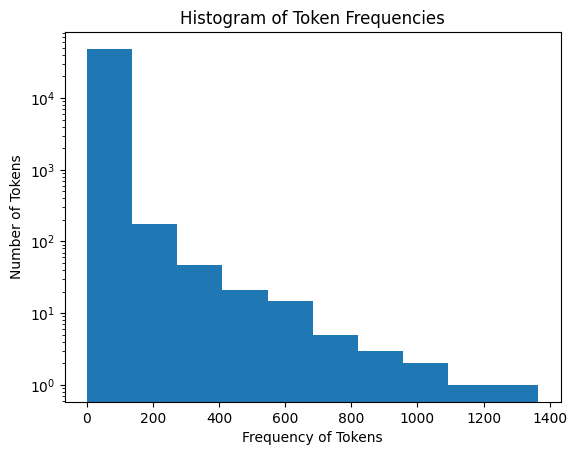

In [2]:
import matplotlib.pyplot as plt 
#Plot a histogram of the occurrences of tokens. 
frequency = [freq for token, freq in token_freq]
plt.hist(frequency, log = True )
plt.xlabel('Frequency of Tokens')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()


**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.metrics import r2_score 
from sklearn.linear_model import LinearRegression

df = pd.read_parquet('data/Phishing_clean.parquet')

## 1. 80/20 train test split
X = df.drop(columns=['Email Type'])
Y = df['Email Type'] 
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

## 2. Fit a linear regression model to the training data
model = LinearRegression()
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Train R^2 Score:", train_r2)
print("Test R^2 Score:", test_r2)

## 3. the largest coefficients in absolute value and most strongly influence predictions? 
coefs = pd.Series(model.coef_, index=X.columns)
abs_top = coefs.abs().nlargest(10)
print("Top 10 features with largest absolute coefficients:")
print(abs_top)

Train R^2 Score: 0.7670143724934355
Test R^2 Score: 0.6658718438847919
Top 10 features with largest absolute coefficients:
intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

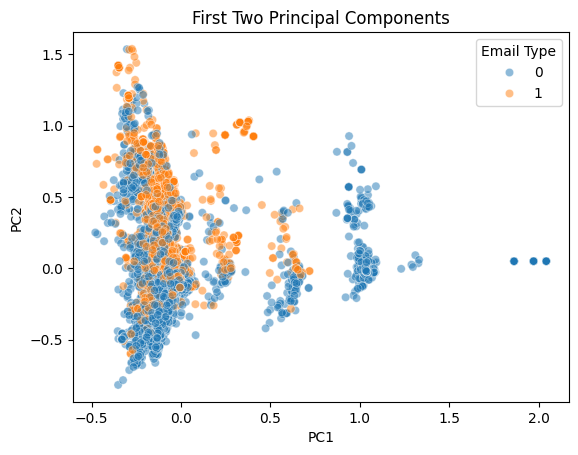

In [11]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = Y.values

sns.scatterplot(data = pca_df, x = 'PC1', y = 'PC2', hue = 'Email Type', alpha = 0.5)
plt.title('First Two Principal Components')
plt.show()

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [12]:
pca = PCA(n_components = 2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)


pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pred_pca = pca_model.predict(X_train_pca)
y_test_pred_pca = pca_model.predict(X_test_pca)

print('Train R^2:', r2_score(y_train, y_train_pred_pca))
print('Test R^2:', r2_score(y_test, y_test_pred_pca))



Train R^2: 0.7662326827745849
Test R^2: 0.6683390643101161


**The linear regressions performance is more effective for this situation**

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The advantage is that it trains way faster because what the PCA does is that it simplifies large and complex datasets by reducing their dimensionality. So when we look at a task like this, where we are trying to run a high-dimensional rgeression, PCA would be way better than just suign the original data.

---

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [6b7e8ebde69308191b616966190041e123e8646e]
- **AI tool and model used:** [Claude]

### *Prompts used

1. [When you look at my code in Phase 1 whta can be altered to better answer the question as well as help with readability.]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. **Q1: Make the histogram show the pattern.** The default 10 bins put nearly every token in the first bar. Use log-spaced bins with both axes on a log scale (`bins=np.logspace(0, np.log10(max(frequency)), 50)`, `plt.xscale('log')`). Or add a rank-vs-frequency plot on log-log axes, where a roughly straight line is Zipf's law.
2. **Q1: Make the answer more specific.** Say that the distribution is heavily right-skewed and close to a power law. Most tokens appear only a few times, and a handful appear thousands of times. Print `token_freq[:10]` as evidence, fix the typo "hsitogram", and move the answer below the plot.
3. **Q2: Show the coefficient signs.** `coefs.abs().nlargest(10)` drops the sign, so you can't tell which words push toward phishing (+) and which toward safe (−). Use `coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)`.
4. **Q2: Add a written answer.** Right now Q2 is code only. Note the gap between train R² (0.767) and test R² (0.666), which points to some overfitting. Also note that the top words are rare tokens and HTML/CSS fragments (`gray;`, `a:active`, `helvetica,`). `gray;` and `a:active` have *identical* coefficients, which suggests perfect collinearity: those tokens always appear together. So the largest coefficients aren't the most meaningful "scam words."
5. **Q3: Label the plot and answer the question.** Map 0/1 to "Legitimate"/"Phishing" in the legend. Add the explained variance to the axis labels (e.g. `PC1 (x.x% var)` from `pca.explained_variance_ratio_`). Then write a short answer, since "Do you notice any patterns?" currently has none. Describe where the two classes separate and where they overlap.
6. **Q3 (optional): Explain what drives the components.** Print the 10 tokens with the largest loadings on PC1 and PC2 (`pca.components_`). That lets you say *why* the classes separate along an axis.
7. **Q4: Fix the conclusion.** "Linear regression is more effective" isn't supported by the numbers. Test R² is 0.668 with PCA and 0.666 without, so the two are essentially the same. Explain that 2,610 of 2,711 components keep almost all the variance, so this is nearly the same model in a rotated basis.
8. **Q4: Don't reuse the name `pca`.** Q4 overwrites the 2-component `pca` from Q3; call them `pca_2` and `pca_full`. Also mention that fitting PCA on `X_train` only correctly avoids test-set leakage.
9. **Q4 (strongest addition): Plot test R² against the number of components.** Try something like [10, 50, 100, 250, 500, 1000, 2610]. If test R² levels off well before 2,610, that's direct evidence for the Q5 answer.
10. **Q5: Rewrite the explanation.** Speed isn't the main point, and with 2,610 components you barely save any time. The real advantages are:
    - The components are uncorrelated, which removes the multicollinearity seen in Q2.
    - Keeping only the top components filters noise and lowers variance and overfitting.
    - You get a stable fit even when features are many, sparse and redundant.
11. **General readability:**
    - Put all imports in one cell at the top.
    - Add a short markdown header and a one-line comment for each step.
    - Format results with f-strings, e.g. `f"Test R²: {test_r2:.3f}"`.
    - Use PEP 8 spacing (`n_components=2`, not `n_components = 2`).
    - Fix typos ("suign", "rgeression").
    - Show the Q2 and Q4 R² values side by side in a small comparison table.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | Kept my Phase 1 histogram for Q1. |
| 2 | Reject | Kept my Phase 1 answer for Q1. |
| 3 | Accept | The Phase 1 code used **coefs.abs().nlargest(10)**, which drops the sign, so it couldn't show whether a word pushes toward phishing or legitimate. The revised code sorts by absolute value but keeps the sign and labels the direction. Verified by re-running Q2: the same top-10 tokens appear as in Phase 1, now with signs. |
| 4 | Accept | Phase 1 had no written answer for Q2. Added an interpretation of the train/test R² gap (0.767 vs. 0.666, some overfitting), and noted that the top tokens are rare words and HTML/CSS fragments. Verified that gray; and a:active` have identical coefficients (0.574), which points to perfect collinearity. |
| 5 | Reject | Kept my Phase 1 Q3 plot. |
| 6 | Reject | Not needed for the Q3 question as asked. |
| 7 | Reject | Kept my Phase 1 Q4 conclusion. |
| 8 | Reject | Kept my Phase 1 Q4 code. |
| 9 | Reject | Extra analysis beyond what Q4 asks for. |
| 10 | Accept | Altered Phase 1 Q5 explanation. Perfomance had nothing to do with speed.|
| 11 | Reject | Kept my Phase 1 formatting outside of Q2. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**Q1**

In [19]:

# Your Phase 2 solution to the problem goes here.
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

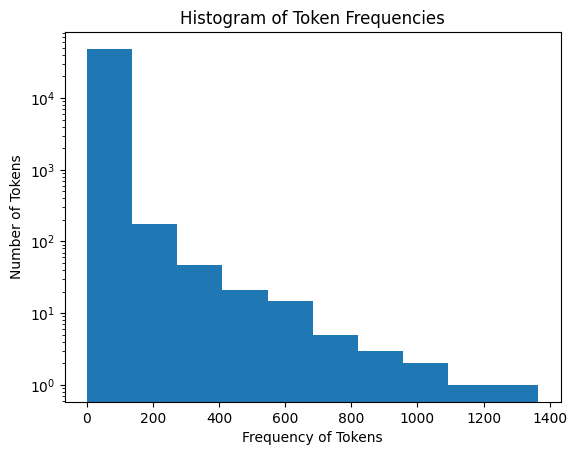

In [20]:
import matplotlib.pyplot as plt 
#Plot a histogram of the occurrences of tokens. 
frequency = [freq for token, freq in token_freq]
plt.hist(frequency, log = True )
plt.xlabel('Frequency of Tokens')
plt.ylabel('Number of Tokens')
plt.title('Histogram of Token Frequencies')
plt.show()

**Q2**

In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split 
from sklearn.metrics import r2_score 
from sklearn.linear_model import LinearRegression
import numpy as np

df = pd.read_parquet('data/Phishing_clean.parquet')

# Q2.1: 80/20 train-test split
X = df.drop(columns=['Email Type'])
y = df['Email Type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Q2.2: Linear regression on the one-hot-encoded tokens
lm = LinearRegression()
lm.fit(X_train, y_train)

lm_train_r2 = r2_score(y_train, lm.predict(X_train))
lm_test_r2 = r2_score(y_test, lm.predict(X_test))
print(f"Train R²: {lm_train_r2:.3f}")
print(f"Test R²:  {lm_test_r2:.3f}")

# Q2.3: Largest coefficients by absolute value, keeping the sign
coefs = pd.Series(lm.coef_, index=X.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
top_coefs_df = pd.DataFrame({
    'coefficient': top_coefs.round(3),
    'pushes toward': np.where(top_coefs > 0, 'phishing', 'legitimate'),
})
display(top_coefs_df)


Train R²: 0.767
Test R²:  0.666


,coefficient,pushes toward
intervention,-1.259,legitimate
localized,0.824,phishing
thermal,0.747,phishing
crawler,0.696,phishing
background-image:,-0.623,legitimate
"helvetica,",0.599,phishing
aging,0.595,phishing
form.,0.577,phishing
gray;,-0.574,legitimate
a:active,0.574,phishing


**Answer:**

1. **Train-test split:** The data was split 80/20 into training and test sets (`random_state=42`).

2. **R²:** The model has a **train R² of about 0.767** and a **test R² of about 0.666**. The model performs noticeably worse on emails it hasn't seen, which suggests some overfitting. That's expected when fitting 2,711 features.

3. **Most influential words:** The tokens with the largest coefficients in absolute value are `intervention` (1.259), `localized` (0.824), `thermal` (0.747), `crawler` (0.696), `background-image:` (0.623), `helvetica,` (0.599), `aging` (0.595), `form.` (0.577), `gray;` (0.574) and `a:active` (0.574). Most of these are not obvious "scam words." They are rare words or fragments of HTML/CSS formatting code. `gray;` and `a:active` have exactly the same coefficient, which suggests they always appear together in the same emails (perfect collinearity), so the model can't separate their effects. The largest coefficients therefore reflect rare, correlated features more than meaningful predictors of phishing, and they should be interpreted with caution.


**Q3**

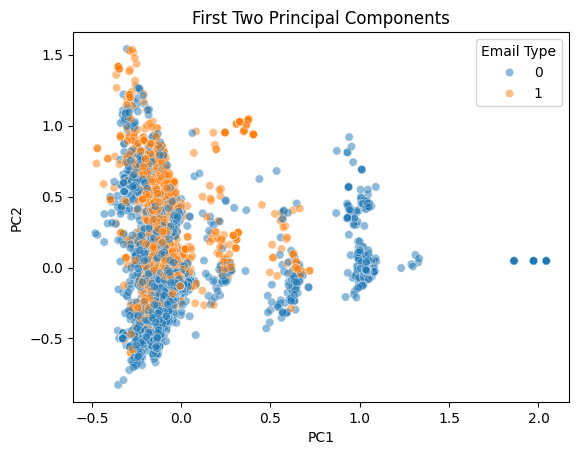

In [22]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X)

pca_df = pd.DataFrame(X_pca, columns = ['PC1', 'PC2'])
pca_df['Email Type'] = Y.values

sns.scatterplot(data = pca_df, x = 'PC1', y = 'PC2', hue = 'Email Type', alpha = 0.5)
plt.title('First Two Principal Components')
plt.show()

**Q4**

In [23]:
pca = PCA(n_components = 2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)


pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

y_train_pred_pca = pca_model.predict(X_train_pca)
y_test_pred_pca = pca_model.predict(X_test_pca)

print('Train R^2:', r2_score(y_train, y_train_pred_pca))
print('Test R^2:', r2_score(y_test, y_test_pred_pca))

Train R^2: 0.7662326827745849
Test R^2: 0.6683390643101161


**The linear regressions performance is more effective for this situation**

**Q5**

- The components are uncorrelated, which removes the multicollinearity seen in Q2.
- Keeping only the top components filters noise and lowers variance and overfitting.
- You get a stable fit even when features are many, sparse and redundant.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements to the code was in question 2. The problem with the code was that it was hiding wich way each word pushes. I was using .abs(), whihc trune every coefficient positive before sorting. Sortign by absolute value is correct but when it's printed out it loses the sign. The next change is in my answer, I'm realizing that it would be best for Q2 to have a written response rather than just havign viewers read through the output summary I had. I also change my response for 5 because I was wya off for my reasoning. Something that I used for verifictaion was the fact that for many for my outputs I got similar values. In asking AI i saw no mistakes or limitations.